## DSC540-T301 Data Preparation
## Term Project — Milestone 5
### Kyle Gotzman

**Data Sources:**
1. **Flat File (Milestone 2):** NCES F-33 School District Finance Survey, FY2023 — `elsec23.xlsx`
2. **Web Scraping (Milestone 3):** Public School Review — NC school district profiles (`publicschoolreview.com`)
3. **API (Milestone 4):** U.S. Census Bureau SAIPE — poverty and income estimates (`api.census.gov`)

### Approach

This milestone loads the three cleaned datasets from Milestones 2, 3, and 4 into a SQLite database as individual tables, merges them using SQL INNER JOINs on the shared `ncesid` key, and produces five visualizations from the consolidated dataset. The cleaning steps from each prior milestone are reproduced below in condensed form so this notebook is fully self-contained and reproducible.

**Note:** Milestone 3 scrapes 116 district pages from Public School Review with a 1.5-second delay between requests (~3 minutes total on first run). The scraped data is cached to `milestone3_scraped.csv` afterward so subsequent runs load instantly.

### Reproduce Milestone 2 — F-33 School District Finance Data

In [1]:
import os, re, json, time, tempfile

# Fix matplotlib cache directory before importing it
os.environ['MPLCONFIGDIR'] = tempfile.mkdtemp()

import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import requests
from bs4 import BeautifulSoup

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.figsize': (12, 7), 'figure.dpi': 100})
print('Imports complete.')

# Load the F-33 flat file (only the columns we need) and filter to North Carolina
KEEP_COLS = ['FIPST','NCESID','NAME','CONUM','V33',
             'TOTALREV','TFEDREV','TSTREV','TLOCREV','TOTALEXP']
df_m2_raw = pd.read_excel(
    'elsec23.xlsx', sheet_name='elsec23',
    usecols=KEEP_COLS,
    dtype={'FIPST': str, 'NCESID': str, 'CONUM': str, 'NAME': str}
)
df_m2 = df_m2_raw[df_m2_raw['FIPST'] == '37'].copy()

# Rename to human-readable column names
df_m2 = df_m2[['NCESID','NAME','CONUM','V33','TOTALREV','TFEDREV',
                'TSTREV','TLOCREV','TOTALEXP']].rename(columns={
    'NCESID':'ncesid', 'NAME':'district_name', 'CONUM':'county_code',
    'V33':'fall_enrollment', 'TOTALREV':'total_revenue',
    'TFEDREV':'federal_revenue', 'TSTREV':'state_revenue',
    'TLOCREV':'local_revenue', 'TOTALEXP':'total_expenditures'
})

# Replace sentinel values (-1, -2, -3) with NaN
for c in df_m2.select_dtypes(include=[np.number]).columns:
    df_m2[c] = df_m2[c].replace([-1, -2, -3], np.nan)

# Convert dollar amounts from thousands to actual dollars
for c in ['total_revenue','federal_revenue','state_revenue','local_revenue','total_expenditures']:
    df_m2[c] = df_m2[c] * 1000

# Compute per-pupil expenditure
df_m2['per_pupil_expenditure'] = (df_m2['total_expenditures'] / df_m2['fall_enrollment']).round(0)

# Standardize district names (Title Case, expand abbreviations)
df_m2['district_name'] = df_m2['district_name'].str.strip().str.title()
for pat, rep in [(r'\bSch\b','Schools'),(r'\bSchs\b','Schools'),
                 (r'\bCo\b','County'),(r'\bDist\b','District'),
                 (r'\bMt\b','Mount'),(r'\bSt\b','Saint'),
                 (r'\bEd\b','Education'),(r'\bPub\b','Public')]:
    df_m2['district_name'] = df_m2['district_name'].str.replace(pat, rep, regex=True)
df_m2['district_name'] = df_m2['district_name'].str.replace(r'\bOf\b', 'of', regex=True)
df_m2['district_name'] = df_m2['district_name'].str.replace(r'\bAnd\b', 'and', regex=True)
df_m2 = df_m2.reset_index(drop=True)

print(f"Milestone 2 — Finance: {df_m2.shape[0]} districts × {df_m2.shape[1]} columns")
print(df_m2[['ncesid','district_name','fall_enrollment','per_pupil_expenditure']].head().to_string())

Matplotlib is building the font cache; this may take a moment.


Imports complete.


Milestone 2 — Finance: 116 districts × 10 columns
    ncesid                    district_name  fall_enrollment  per_pupil_expenditure
0  3700210              Ashe County Schools             2743                15511.0
1  3700360            Bertie County Schools             1831                17611.0
2  3700480  Burke County Board of Education            11770                13067.0
3  3700780          Cherokee County Schools             3146                14715.0
4  3704920          Whiteville City Schools             2104                15620.0


### Reproduce Milestone 3 — Public School Review Performance Data

In [2]:
M3_CACHE = 'milestone3_scraped.csv'

if os.path.exists(M3_CACHE):
    df_m3 = pd.read_csv(M3_CACHE, dtype={'ncesid': str})
    print(f"Loaded Milestone 3 from cache: {df_m3.shape}")
else:
    nc_ids = df_m2_raw.loc[df_m2_raw['FIPST'] == '37', 'NCESID'].tolist()
    HEADERS = {'User-Agent': 'Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36'}
    BASE_URL = 'https://www.publicschoolreview.com/north-carolina/x/{ncesid}-school-district'
    PLOTLY_MAP = {
        'Overall_District_Rank':'district_rank','District_Math_Percent':'math_proficiency_pct',
        'District_RLA_Percent':'reading_proficiency_pct','District_SCI_Percent':'science_proficiency_pct',
        'District_Graduation_Rate':'graduation_rate_pct','District_Diversity_Score':'diversity_score',
        'Asian_Islander_Ethnicity':'asian_pct','Hispanic_Students_Ethnicity':'hispanic_pct',
        'Black_Students_Ethnicity':'black_pct','White_Students_Ethnicity':'white_pct',
        'Two_Or_More_Races_Students_Ethnicity':'two_or_more_races_pct',
        'American_Indian_Ethnicity':'american_indian_pct',
        'District_Total_Revenue':'total_revenue_mm','District_Spending':'total_expenditure_mm',
        'District_Revenue_Ratio':'revenue_per_student','District_Spending_Ratio':'expenditure_per_student',
    }

    def _li_val(soup, kw):
        for li in soup.find_all('li'):
            t = li.get_text(strip=True)
            if kw.lower() in t.lower():
                parts = t.split(':')
                return parts[1].strip() if len(parts) > 1 else t
        return None

    def _plotly(soup):
        for s in soup.find_all('script'):
            txt = s.string or ''
            if 'plotlyChartsJsonData' in txt:
                m = re.search(r'var plotlyChartsJsonData=(\{.*?\});\s', txt, re.DOTALL)
                if m: return json.loads(m.group(1))
        return {}

    def _latest(cd, key):
        tr = cd.get(key, [])
        return tr[0]['y'][-1] if tr and tr[0].get('y') else None

    def _scrape(ncesid):
        url = BASE_URL.format(ncesid=ncesid)
        try:
            r = requests.get(url, headers=HEADERS, allow_redirects=True, timeout=15)
            r.raise_for_status()
        except requests.RequestException as e:
            return {'ncesid': ncesid, '_error': str(e)}
        soup = BeautifulSoup(r.text, 'html.parser')
        h1 = soup.find('h1')
        row = {'ncesid': ncesid,
               'district_name': h1.get_text(strip=True) if h1 else None,
               'enrollment': _li_val(soup, 'Enrollment'),
               'student_teacher_ratio': _li_val(soup, 'Student-Teacher Ratio'),
               'minority_enrollment_pct': _li_val(soup, 'Minority Enrollment'),
               'num_schools': _li_val(soup, 'District size')}
        cd = _plotly(soup)
        for pk, cn in PLOTLY_MAP.items():
            row[cn] = _latest(cd, pk)
        return row

    print('Scraping 116 NC districts from Public School Review (~3 min)...')
    records = []
    for i, nid in enumerate(nc_ids):
        row = _scrape(nid)
        if '_error' not in row:
            records.append(row)
        if (i + 1) % 20 == 0 or (i + 1) == len(nc_ids):
            print(f'  {i + 1}/{len(nc_ids)} scraped')
        time.sleep(1.5)

    df_m3 = pd.DataFrame(records)

    # Clean text-based fields
    df_m3['enrollment'] = pd.to_numeric(
        df_m3['enrollment'].astype(str).str.replace(r'[^\d]', '', regex=True), errors='coerce').astype('Int64')
    df_m3['num_schools'] = pd.to_numeric(
        df_m3['num_schools'].astype(str).str.replace(r'[^\d]', '', regex=True), errors='coerce').astype('Int64')
    df_m3['student_teacher_ratio'] = (
        df_m3['student_teacher_ratio'].astype(str).str.extract(r'(\d+\.?\d*)')[0].astype(float))
    df_m3['minority_enrollment_pct'] = pd.to_numeric(
        df_m3['minority_enrollment_pct'].astype(str).str.replace(r'[^\d.]', '', regex=True), errors='coerce')
    for c in PLOTLY_MAP.values():
        df_m3[c] = pd.to_numeric(df_m3[c], errors='coerce')

    # Convert aggregate financials from millions to actual dollars
    df_m3['total_revenue'] = df_m3['total_revenue_mm'] * 1_000_000
    df_m3['total_expenditure'] = df_m3['total_expenditure_mm'] * 1_000_000
    df_m3 = df_m3.drop(columns=['total_revenue_mm', 'total_expenditure_mm'])

    # Standardize district names
    df_m3['district_name'] = df_m3['district_name'].str.strip().str.title()

    df_m3.to_csv(M3_CACHE, index=False)
    print(f'Saved {len(df_m3)} districts to {M3_CACHE}')

print(f'\nMilestone 3 \u2014 Performance: {df_m3.shape[0]} districts \u00d7 {df_m3.shape[1]} columns')
print(df_m3[['ncesid','district_name','math_proficiency_pct','graduation_rate_pct']].head().to_string())

Scraping 116 NC districts from Public School Review (~3 min)...


  20/116 scraped


  40/116 scraped


  60/116 scraped


  80/116 scraped


  100/116 scraped


  116/116 scraped


Saved 116 districts to milestone3_scraped.csv

Milestone 3 — Performance: 116 districts × 22 columns
    ncesid            district_name  math_proficiency_pct  graduation_rate_pct
0  3700210      Ashe County Schools                    65                   82
1  3700360    Bertie County Schools                    31                   92
2  3700480     Burke County Schools                    54                   88
3  3700780  Cherokee County Schools                    50                   91
4  3704920  Whiteville City Schools                    58                   87


### Reproduce Milestone 4 — SAIPE Poverty & Income Data

In [3]:
API_KEY = os.environ.get('CENSUS_API_KEY', '')
if not API_KEY:
    raise RuntimeError('Set the CENSUS_API_KEY environment variable. Request a free key at https://api.census.gov/data/key_signup.html')

# School-district endpoint
r_dist = requests.get(
    'https://api.census.gov/data/timeseries/poverty/saipe/schdist'
    '?get=SD_NAME,SAEPOV5_17RV_PT,SAEPOV5_17V_PT,SAEPOVRAT5_17RV_PT,SAEPOVALL_PT,LEAID,GRADE'
    '&for=school+district+(unified):*&in=state:37&time=2023'
    f'&key={API_KEY}', timeout=30)
r_dist.raise_for_status()
dj = r_dist.json()
df_m4 = pd.DataFrame(dj[1:], columns=dj[0])

# County endpoint (median household income)
r_cty = requests.get(
    'https://api.census.gov/data/timeseries/poverty/saipe'
    '?get=NAME,SAEMHI_PT,SAEPOVRTALL_PT,COUNTY'
    '&for=county:*&in=state:37&time=2023'
    f'&key={API_KEY}', timeout=30)
r_cty.raise_for_status()
cj = r_cty.json()
df_cty = pd.DataFrame(cj[1:], columns=cj[0])

# Rename and type-cast district data
df_m4 = df_m4.rename(columns={
    'SD_NAME':'district_name', 'SAEPOV5_17RV_PT':'poverty_count_5_17',
    'SAEPOV5_17V_PT':'population_5_17', 'SAEPOVRAT5_17RV_PT':'poverty_rate_5_17',
    'SAEPOVALL_PT':'total_population', 'LEAID':'leaid', 'GRADE':'grade_range'
})
for c in ['poverty_count_5_17','population_5_17','total_population']:
    df_m4[c] = pd.to_numeric(df_m4[c], errors='coerce').astype('Int64')
df_m4['poverty_rate_5_17'] = pd.to_numeric(df_m4['poverty_rate_5_17'], errors='coerce')

# Construct 7-digit NCESID (state FIPS + LEAID)
df_m4['ncesid'] = df_m4['state'] + df_m4['leaid']

# Clean county data
df_cty = df_cty.rename(columns={
    'NAME':'county_name', 'SAEMHI_PT':'median_household_income',
    'SAEPOVRTALL_PT':'county_poverty_rate_all_ages', 'COUNTY':'county_fips'
})
df_cty['median_household_income'] = pd.to_numeric(df_cty['median_household_income'], errors='coerce')
df_cty['county_poverty_rate_all_ages'] = pd.to_numeric(df_cty['county_poverty_rate_all_ages'], errors='coerce')
df_cty = df_cty[['county_fips','county_name','median_household_income','county_poverty_rate_all_ages']]

# Build district-to-county crosswalk from Milestone 2 flat file
xwalk = df_m2_raw.loc[df_m2_raw['FIPST']=='37', ['NCESID','CONUM']].copy()
xwalk['county_fips'] = xwalk['CONUM'].str[2:]
xwalk = xwalk.rename(columns={'NCESID':'ncesid'})

# Enrich districts with county-level income data
df_m4 = df_m4.merge(xwalk[['ncesid','county_fips']], on='ncesid', how='left')
df_m4 = df_m4.merge(df_cty, on='county_fips', how='left')

# Drop redundant API columns and standardize names
df_m4 = df_m4.drop(columns=['state','school district (unified)','time'], errors='ignore')
df_m4['district_name'] = df_m4['district_name'].str.strip().str.title()

print(f'Milestone 4 \u2014 Poverty & Income: {df_m4.shape[0]} districts \u00d7 {df_m4.shape[1]} columns')
print(df_m4[['ncesid','district_name','poverty_rate_5_17','median_household_income']].head().to_string())

Milestone 4 — Poverty & Income: 118 districts × 12 columns
    ncesid                district_name  poverty_rate_5_17  median_household_income
0  3700011    Cumberland County Schools               21.9                  61511.0
1  3700012          Pitt County Schools               23.7                  60268.0
2  3700030  Alamance-Burlington Schools               14.1                  66395.0
3  3700090     Alexander County Schools               16.6                  62976.0
4  3700120     Alleghany County Schools               23.4                  46571.0


### Load into SQLite Database and Merge with SQL Joins

In [4]:
DB_PATH = 'nc_school_districts.db'
conn = sqlite3.connect(DB_PATH)

# Load each cleaned dataset as a separate table
df_m2.to_sql('finance', conn, if_exists='replace', index=False)
df_m3.to_sql('performance', conn, if_exists='replace', index=False)
df_m4.to_sql('poverty', conn, if_exists='replace', index=False)

print(f'Database created: {DB_PATH}\n')
for tbl in ['finance', 'performance', 'poverty']:
    count = pd.read_sql(f'SELECT COUNT(*) AS n FROM {tbl}', conn).iloc[0, 0]
    cols = pd.read_sql(f'PRAGMA table_info({tbl})', conn)
    print(f'  {tbl}: {count} rows \u00d7 {len(cols)} columns')

# Merge all three tables with SQL INNER JOINs on ncesid
JOIN_SQL = """
SELECT
    f.ncesid,
    f.district_name,
    f.fall_enrollment,
    f.total_revenue       AS f33_total_revenue,
    f.federal_revenue,
    f.state_revenue,
    f.local_revenue,
    f.total_expenditures  AS f33_total_expenditures,
    f.per_pupil_expenditure,
    p.math_proficiency_pct,
    p.reading_proficiency_pct,
    p.science_proficiency_pct,
    p.graduation_rate_pct,
    p.diversity_score,
    p.student_teacher_ratio,
    p.minority_enrollment_pct,
    p.expenditure_per_student AS psr_per_pupil_exp,
    s.poverty_rate_5_17,
    s.poverty_count_5_17,
    s.population_5_17,
    s.total_population,
    s.median_household_income,
    s.county_name,
    s.county_poverty_rate_all_ages
FROM finance f
INNER JOIN performance p ON f.ncesid = p.ncesid
INNER JOIN poverty s    ON f.ncesid = s.ncesid
WHERE s.median_household_income IS NOT NULL
ORDER BY f.fall_enrollment DESC
"""
df_merged = pd.read_sql(JOIN_SQL, conn)
conn.close()

print(f'\nMerged dataset: {df_merged.shape[0]} districts \u00d7 {df_merged.shape[1]} columns')
print(f'\n{df_merged[["district_name","fall_enrollment","per_pupil_expenditure","math_proficiency_pct","poverty_rate_5_17","median_household_income"]].head(10).to_string()}')

Database created: nc_school_districts.db

  finance: 116 rows × 10 columns
  performance: 116 rows × 22 columns
  poverty: 118 rows × 12 columns

Merged dataset: 115 districts × 24 columns

                          district_name  fall_enrollment  per_pupil_expenditure  math_proficiency_pct  poverty_rate_5_17  median_household_income
0                   Wake County Schools           159778                13702.0                    60                8.0                 103084.0
1         Charlotte-Mecklenburg Schools           144197                16641.0                    52               13.8                  84796.0
2               Guilford County Schools            68894                14585.0                    46               19.2                  65890.0
3  Forsyth County-Winston Salem Schools            52717                15007.0                    42               20.4                  65556.0
4             Cumberland County Schools            49661                13291.0 

### Visualizations

Five visualizations are presented below. Visualizations 1, 2, 4, and 5 combine data from multiple source tables (joined via SQL). Visualization 3 uses data from the finance table alone.

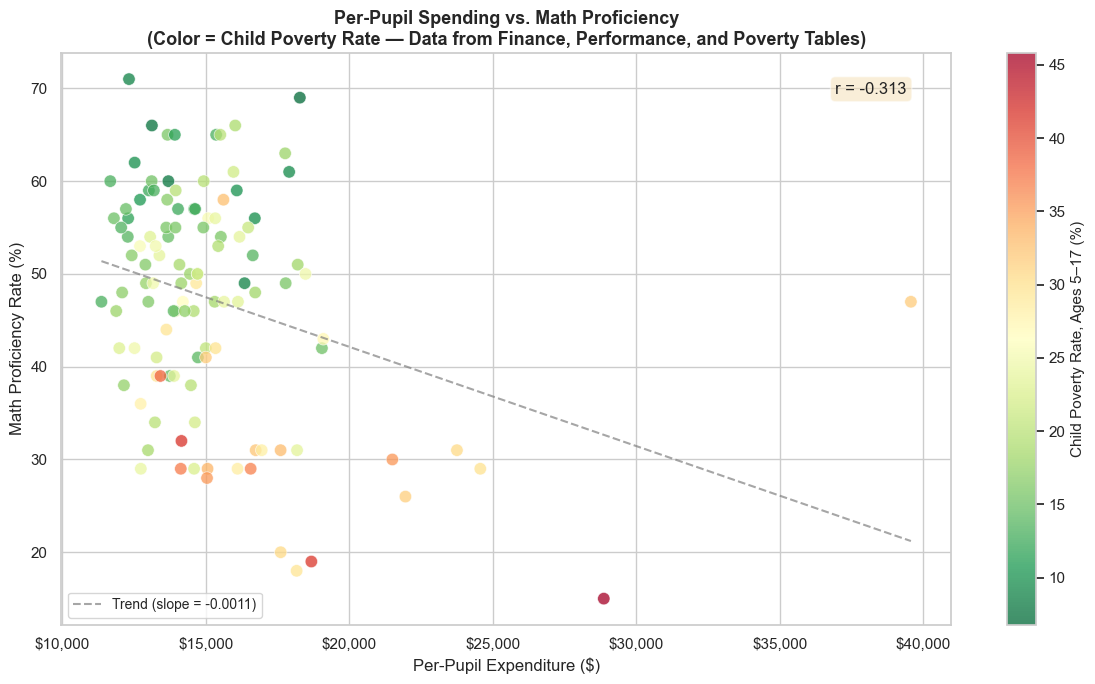

In [5]:
# Visualization 1: Per-Pupil Spending vs. Math Proficiency
# Sources: finance (per_pupil_expenditure) + performance (math_proficiency_pct)
#          + poverty (poverty_rate_5_17)

fig, ax = plt.subplots(figsize=(12, 7))

scatter = ax.scatter(
    df_merged['per_pupil_expenditure'],
    df_merged['math_proficiency_pct'],
    c=df_merged['poverty_rate_5_17'],
    cmap='RdYlGn_r', s=80, alpha=0.75,
    edgecolors='white', linewidth=0.5
)
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Child Poverty Rate, Ages 5\u201317 (%)', fontsize=11)

z = np.polyfit(df_merged['per_pupil_expenditure'], df_merged['math_proficiency_pct'], 1)
x_line = np.linspace(df_merged['per_pupil_expenditure'].min(),
                     df_merged['per_pupil_expenditure'].max(), 100)
ax.plot(x_line, np.polyval(z, x_line), '--', color='gray', alpha=0.7,
        label=f'Trend (slope = {z[0]:.4f})')

r = df_merged['per_pupil_expenditure'].corr(df_merged['math_proficiency_pct'])
ax.text(0.95, 0.95, f'r = {r:.3f}', transform=ax.transAxes, fontsize=12,
        ha='right', va='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

ax.set_xlabel('Per-Pupil Expenditure ($)', fontsize=12)
ax.set_ylabel('Math Proficiency Rate (%)', fontsize=12)
ax.set_title('Per-Pupil Spending vs. Math Proficiency\n'
             '(Color = Child Poverty Rate \u2014 Data from Finance, Performance, and Poverty Tables)',
             fontsize=13, fontweight='bold')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

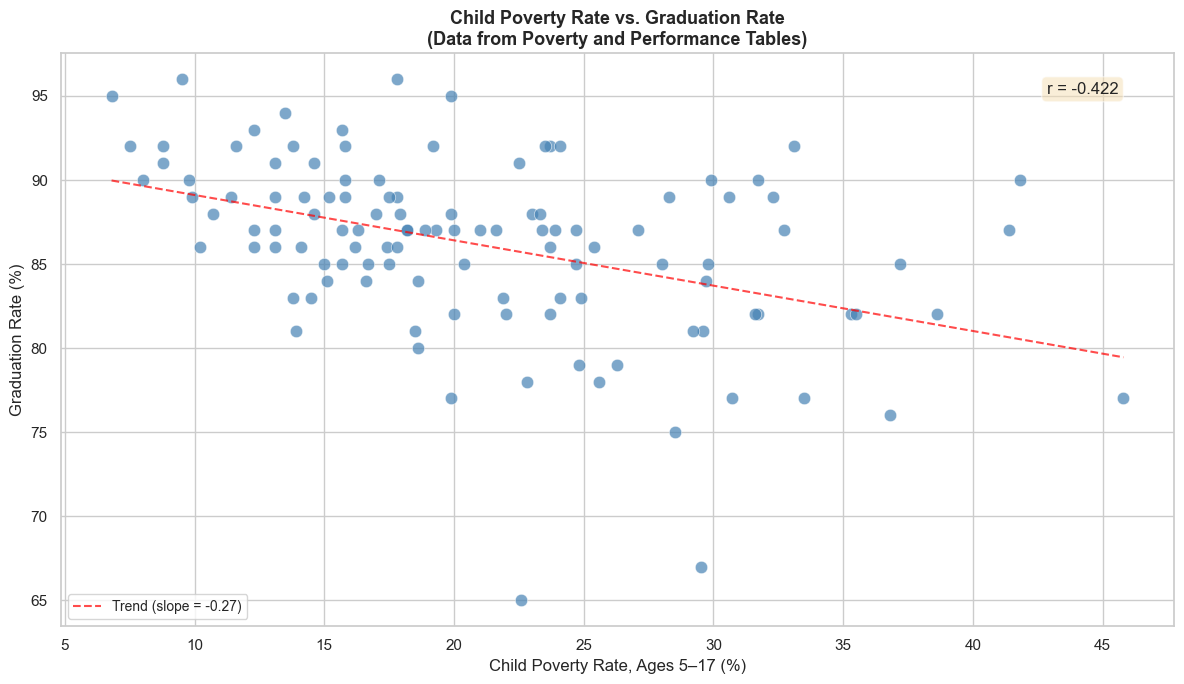

In [6]:
# Visualization 2: Child Poverty Rate vs. Graduation Rate
# Sources: poverty (poverty_rate_5_17) + performance (graduation_rate_pct)

fig, ax = plt.subplots(figsize=(12, 7))

ax.scatter(df_merged['poverty_rate_5_17'], df_merged['graduation_rate_pct'],
           c='steelblue', s=80, alpha=0.7, edgecolors='white', linewidth=0.5)

z = np.polyfit(df_merged['poverty_rate_5_17'], df_merged['graduation_rate_pct'], 1)
x_line = np.linspace(df_merged['poverty_rate_5_17'].min(),
                     df_merged['poverty_rate_5_17'].max(), 100)
ax.plot(x_line, np.polyval(z, x_line), '--', color='red', alpha=0.7,
        label=f'Trend (slope = {z[0]:.2f})')

r = df_merged['poverty_rate_5_17'].corr(df_merged['graduation_rate_pct'])
ax.text(0.95, 0.95, f'r = {r:.3f}', transform=ax.transAxes, fontsize=12,
        ha='right', va='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

ax.set_xlabel('Child Poverty Rate, Ages 5\u201317 (%)', fontsize=12)
ax.set_ylabel('Graduation Rate (%)', fontsize=12)
ax.set_title('Child Poverty Rate vs. Graduation Rate\n'
             '(Data from Poverty and Performance Tables)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

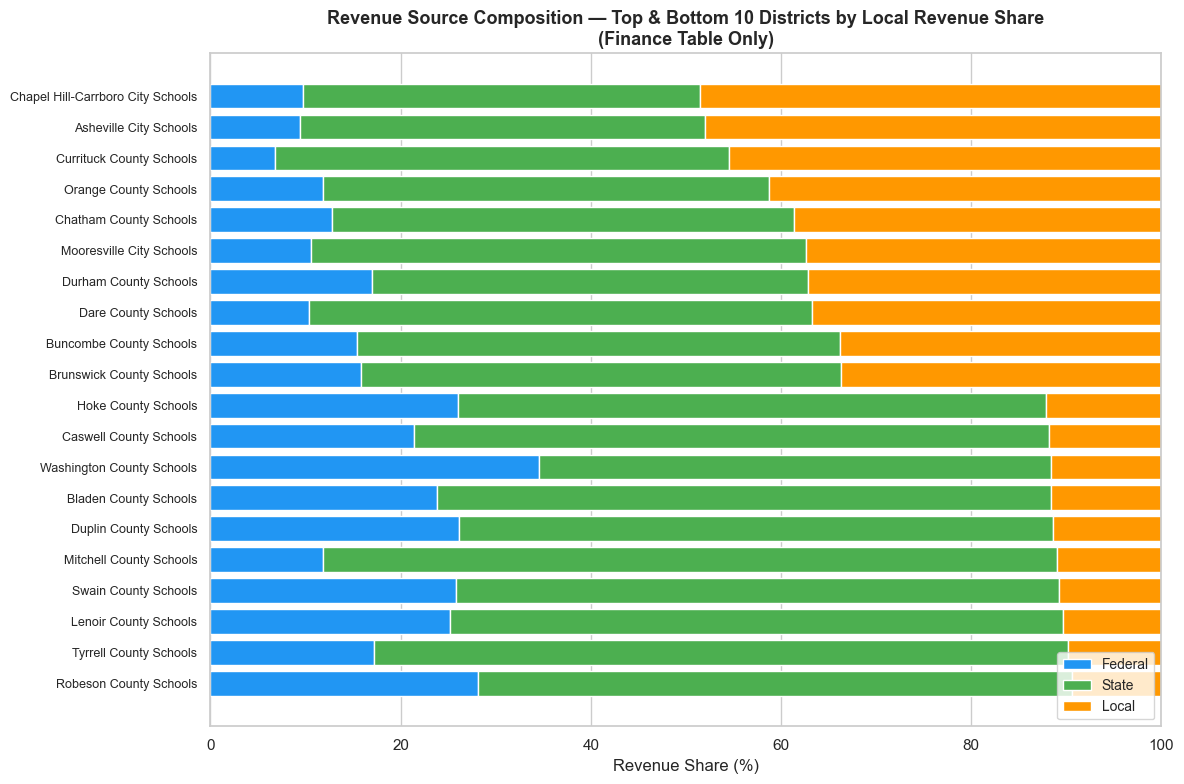

In [7]:
# Visualization 3: Revenue Source Composition (Top & Bottom 10 by Local Share)
# Source: finance table only

fig, ax = plt.subplots(figsize=(12, 8))

df_rev = df_merged[['district_name','federal_revenue','state_revenue','local_revenue']].copy()
total = df_rev['federal_revenue'] + df_rev['state_revenue'] + df_rev['local_revenue']
df_rev['federal_pct'] = df_rev['federal_revenue'] / total * 100
df_rev['state_pct']   = df_rev['state_revenue']   / total * 100
df_rev['local_pct']   = df_rev['local_revenue']   / total * 100

df_rev = df_rev.sort_values('local_pct', ascending=True)
df_show = pd.concat([df_rev.head(10), df_rev.tail(10)]).reset_index(drop=True)

y = range(len(df_show))
ax.barh(y, df_show['federal_pct'], label='Federal', color='#2196F3')
ax.barh(y, df_show['state_pct'], left=df_show['federal_pct'], label='State', color='#4CAF50')
ax.barh(y, df_show['local_pct'],
        left=df_show['federal_pct'] + df_show['state_pct'], label='Local', color='#FF9800')

ax.set_yticks(list(y))
ax.set_yticklabels(df_show['district_name'], fontsize=9)
ax.set_xlabel('Revenue Share (%)', fontsize=12)
ax.set_title('Revenue Source Composition \u2014 Top & Bottom 10 Districts by Local Revenue Share\n'
             '(Finance Table Only)',
             fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

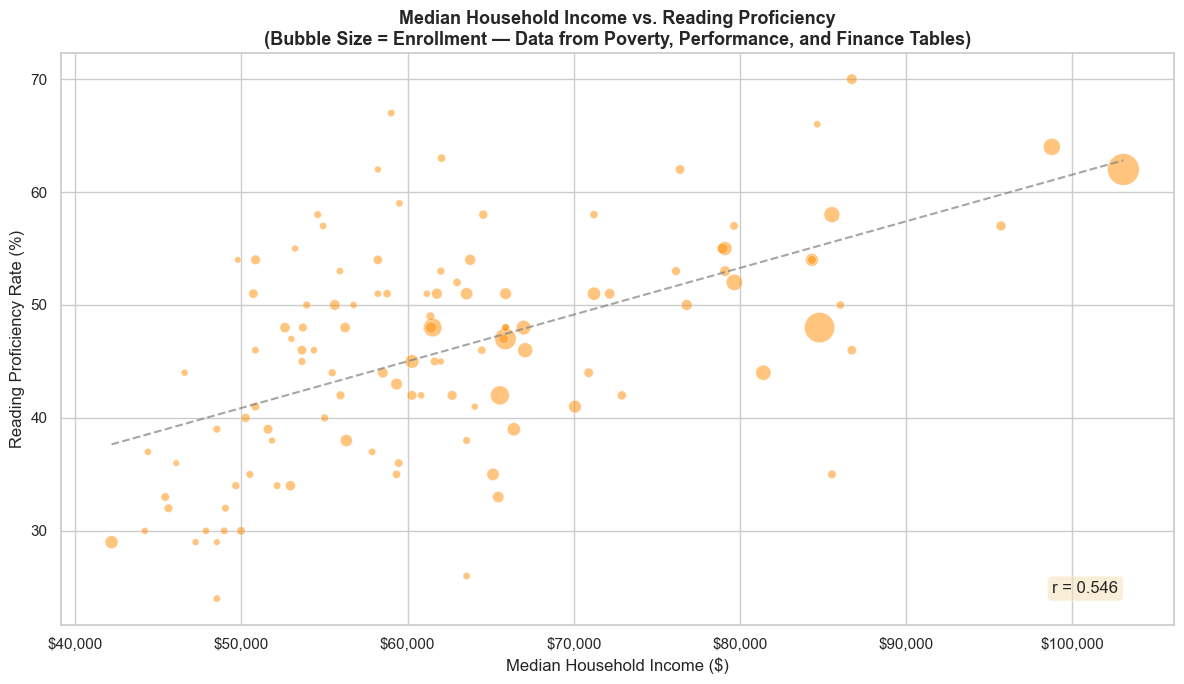

In [8]:
# Visualization 4: Median Household Income vs. Reading Proficiency
# Sources: poverty (median_household_income) + performance (reading_proficiency_pct)
#          + finance (fall_enrollment for bubble size)

fig, ax = plt.subplots(figsize=(12, 7))

sizes = df_merged['fall_enrollment'] / df_merged['fall_enrollment'].max() * 500 + 20
ax.scatter(df_merged['median_household_income'], df_merged['reading_proficiency_pct'],
           s=sizes, alpha=0.5, c='darkorange', edgecolors='white', linewidth=0.5)

z = np.polyfit(df_merged['median_household_income'], df_merged['reading_proficiency_pct'], 1)
x_line = np.linspace(df_merged['median_household_income'].min(),
                     df_merged['median_household_income'].max(), 100)
ax.plot(x_line, np.polyval(z, x_line), '--', color='gray', alpha=0.7)

r = df_merged['median_household_income'].corr(df_merged['reading_proficiency_pct'])
ax.text(0.95, 0.05, f'r = {r:.3f}', transform=ax.transAxes, fontsize=12,
        ha='right', va='bottom', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

ax.set_xlabel('Median Household Income ($)', fontsize=12)
ax.set_ylabel('Reading Proficiency Rate (%)', fontsize=12)
ax.set_title('Median Household Income vs. Reading Proficiency\n'
             '(Bubble Size = Enrollment \u2014 Data from Poverty, Performance, and Finance Tables)',
             fontsize=13, fontweight='bold')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
plt.tight_layout()
plt.show()

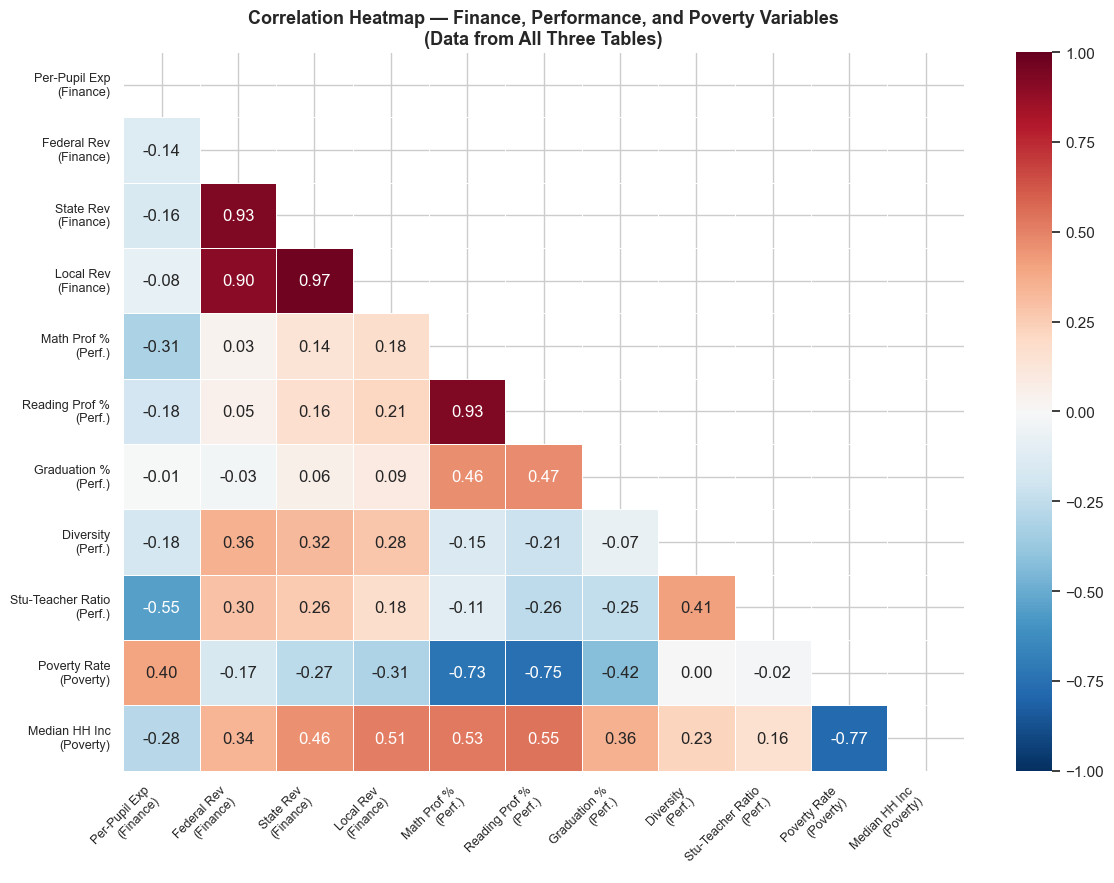

In [9]:
# Visualization 5: Correlation Heatmap \u2014 Key Variables from All Three Tables
# Sources: finance + performance + poverty

fig, ax = plt.subplots(figsize=(12, 9))

corr_cols = ['per_pupil_expenditure','federal_revenue','state_revenue','local_revenue',
             'math_proficiency_pct','reading_proficiency_pct','graduation_rate_pct',
             'diversity_score','student_teacher_ratio',
             'poverty_rate_5_17','median_household_income']
labels = ['Per-Pupil Exp\n(Finance)','Federal Rev\n(Finance)','State Rev\n(Finance)',
          'Local Rev\n(Finance)','Math Prof %\n(Perf.)','Reading Prof %\n(Perf.)',
          'Graduation %\n(Perf.)','Diversity\n(Perf.)','Stu-Teacher Ratio\n(Perf.)',
          'Poverty Rate\n(Poverty)','Median HH Inc\n(Poverty)']

corr = df_merged[corr_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            xticklabels=labels, yticklabels=labels,
            center=0, vmin=-1, vmax=1, linewidths=0.5, ax=ax)

ax.set_title('Correlation Heatmap \u2014 Finance, Performance, and Poverty Variables\n'
             '(Data from All Three Tables)',
             fontsize=13, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()

### Summary

This term project examined the relationship between school district spending, poverty, and student outcomes across 116 North Carolina school districts using three distinct data sources: (1) the NCES F-33 School District Finance Survey from the U.S. Census Bureau (flat file), providing detailed revenue and expenditure data; (2) Public School Review (web scraping), supplying academic proficiency rates, graduation rates, and demographic profiles; and (3) the Census Bureau Small Area Income and Poverty Estimates API (SAIPE), contributing district-level child poverty rates and county-level median household income.

**Data Preparation Process.** Each dataset required distinct cleaning strategies. The F-33 flat file contained 183 columns with cryptic variable codes and dollar amounts expressed in thousands; these were renamed, converted to actual dollars, and sentinel values (-1, -2, -3) were replaced with NaN. The web-scraped data arrived as a mix of HTML text fields and embedded Plotly chart JSON, requiring parsing of multiple data formats from 116 individual district pages. The API data returned all values as strings with coded variable names that needed renaming and type conversion. Across all three sources, district names were standardized to title case with expanded abbreviations to enable reliable joining on the NCESID, a 7-digit identifier shared by all datasets. All three cleaned datasets were loaded into a SQLite database as individual tables and merged via SQL INNER JOINs on the NCESID key, producing a consolidated dataset of 115 districts with 24 variables spanning finance, performance, and poverty dimensions.

**Key Findings.** The visualizations reveal that per-pupil spending alone is a weak predictor of academic performance, districts with higher expenditures do not consistently produce higher math proficiency scores. In contrast, child poverty rate shows a strong negative correlation with graduation rate, suggesting that socioeconomic context is more predictive of student outcomes than spending levels. Median household income correlates positively with reading proficiency, reinforcing this pattern. The revenue composition analysis reveals that lower-income districts rely more heavily on federal and state funding, while wealthier districts derive a larger share from local property taxes.

**Ethical Implications.** Cleansing data inherently involves editorial decisions that can shape analytical conclusions. Replacing sentinel values with NaN, flagging outliers, and standardizing names all introduce assumptions. The ecological fallacy is a key concern: county-level income data was used as a proxy for district-level economic conditions, which may not reflect the actual financial circumstances of families within each district. Preserving the full dataset without removing outliers, documenting all transformations, and cross-validating between independent data sources helped mitigate these risks. The data was ethically acquired from public federal sources with no individual-level information, but care must be taken not to stigmatize individual districts based on aggregate statistics.